In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 19           
rng = np.random.default_rng(SEED)

PRIORS = [0.3, 0.4, 0.3]
MEANS = np.array([[-10, 0, 10], [0, 0, 0], [10, 0, -10]], dtype=float)  
COVS = np.zeros((3, 3, 3))
COVS[:, :, 0] = [[1, 0, -3], [0, 1, 0], [-3, 0, 15]]
COVS[:, :, 1] = [[8, 0, 0], [0, .5, 0], [0, 0, .5]]
COVS[:, :, 2] = [[1, 0, -3], [0, 1, 0], [-3, 0, 15]]

def generate_data(N, rng):
    u = rng.random(N)
    comp = (u > 0.3).astype(int) + (u > 0.7).astype(int)    
    d = np.zeros((N, 3))
    for k in range(3):
        idx = comp == k
        L = np.linalg.cholesky(COVS[:, :, k])
        d[idx] = MEANS[:, k] + rng.standard_normal((idx.sum(), 3)) @ L.T
    return d[:, :2], d[:, 2]          # x = (x1, x2), y

Xtrain, ytrain = generate_data(100, rng)
Xval, yval = generate_data(1000, rng)
print(f"Training samples: {len(ytrain)},  validation samples: {len(yval)}")

Training samples: 100,  validation samples: 1000


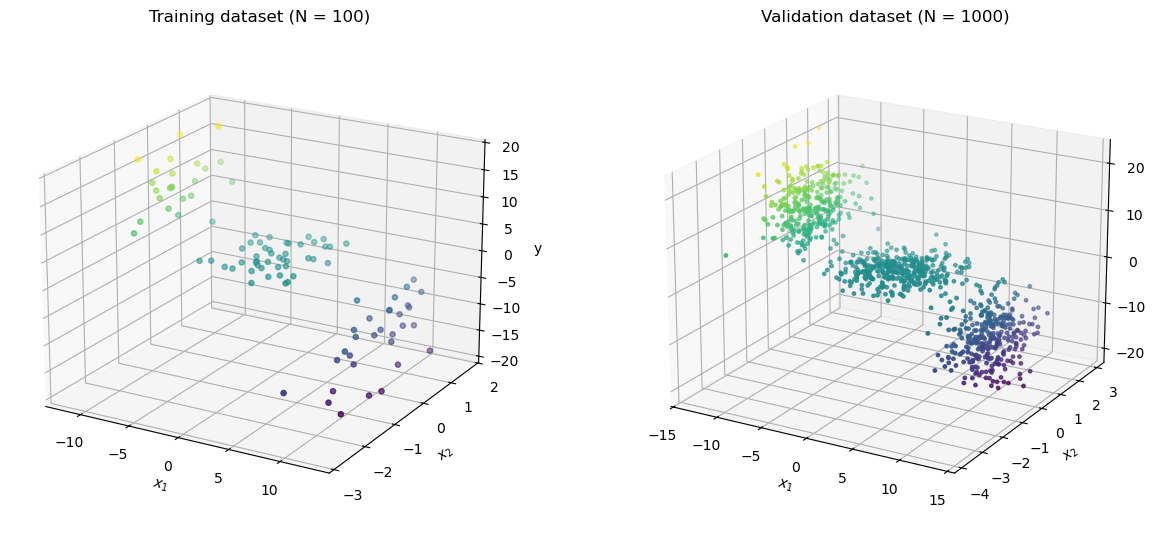

In [2]:
fig = plt.figure(figsize=(13, 5.5))
for i, (X, y, title) in enumerate([(Xtrain, ytrain, "Training dataset (N = 100)"),
                                   (Xval, yval, "Validation dataset (N = 1000)")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.scatter(X[:, 0], X[:, 1], y, s=6 if len(y) > 100 else 14, c=y, cmap="viridis")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("y"); ax.set_title(title)
    ax.view_init(elev=20, azim=-60)
plt.tight_layout(); plt.show()

In [3]:
FEATURE_NAMES = ["1", "x1", "x2", "x1^2", "x1*x2", "x2^2", "x1^3", "x1^2*x2", "x1*x2^2", "x2^3"]

def phi(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(x1)), x1, x2, x1**2, x1*x2, x2**2,
                            x1**3, x1**2*x2, x1*x2**2, x2**3])

def mse(Phi, y, w):
    return np.mean((y - Phi @ w) ** 2)

Phi_tr, Phi_val = phi(Xtrain), phi(Xval)

w_ml = np.linalg.solve(Phi_tr.T @ Phi_tr, Phi_tr.T @ ytrain)
sigma2_hat = mse(Phi_tr, ytrain, w_ml)     
mse_ml_val = mse(Phi_val, yval, w_ml)

print("w_ML =", np.round(w_ml, 4))
print(f"Estimated noise variance sigma^2 = {sigma2_hat:.3f}")
print(f"ML training MSE   = {sigma2_hat:.3f}")
print(f"ML validation MSE = {mse_ml_val:.3f}")

w_ML = [-0.2579  0.0267  0.1033  0.0076 -0.0021  0.0526 -0.0096  0.0022 -0.0541
 -0.0007]
Estimated noise variance sigma^2 = 3.729
ML training MSE   = 3.729
ML validation MSE = 4.874


In [4]:
def w_map(gamma):
    lam = sigma2_hat / gamma
    return np.linalg.solve(Phi_tr.T @ Phi_tr + lam * np.eye(10), Phi_tr.T @ ytrain)

gammas = np.logspace(-12, 8, 201)                    
W = np.array([w_map(g) for g in gammas])
mse_val = np.array([mse(Phi_val, yval, w) for w in W])
mse_tr  = np.array([mse(Phi_tr, ytrain, w) for w in W])
k_best = np.argmin(mse_val)
g_best, w_best = gammas[k_best], W[k_best]

print(f"{'gamma':>10s}{'train MSE':>12s}{'val MSE':>10s}")
for g in [1e-12, 1e-10, 1e-8, 1e-7, 1e-6, g_best, 1e-5, 1e-4, 1e-2, 1, 1e2, 1e4, 1e8]:
    k = np.argmin(np.abs(np.log10(gammas) - np.log10(g)))
    tag = "  <- best" if k == k_best else ""
    print(f"{gammas[k]:10.1e}{mse_tr[k]:12.3f}{mse_val[k]:10.3f}{tag}")
print(f"\nBest gamma = {g_best:.2e},  best MAP validation MSE = {mse_val[k_best]:.3f}")
print(f"ML validation MSE = {mse_ml_val:.3f}  ->  improvement = {100*(1 - mse_val[k_best]/mse_ml_val):.1f}%")
print(f"Error of always predicting y = 0 (mean of y^2 on validation) = {np.mean(yval**2):.2f}")

     gamma   train MSE   val MSE
   1.0e-12      74.198    72.434
   1.0e-10      73.927    72.169
   1.0e-08      53.150    51.859
   1.0e-07      12.224    11.946
   1.0e-06       4.340     4.422
   2.5e-06       4.134     4.322  <- best
   1.0e-05       3.997     4.397
   1.0e-04       3.894     4.548
   1.0e-02       3.752     4.783
   1.0e+00       3.730     4.861
   1.0e+02       3.729     4.874
   1.0e+04       3.729     4.874
   1.0e+08       3.729     4.874

Best gamma = 2.51e-06,  best MAP validation MSE = 4.322
ML validation MSE = 4.874  ->  improvement = 11.3%
Error of always predicting y = 0 (mean of y^2 on validation) = 72.44


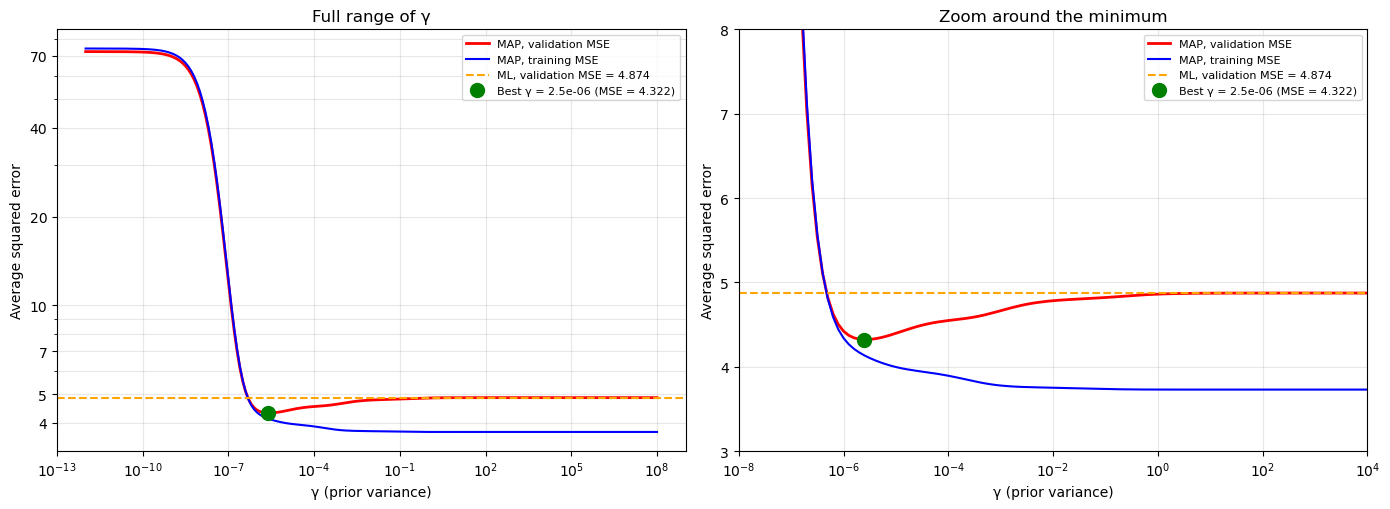

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, zoom in zip(axes, [False, True]):
    ax.semilogx(gammas, mse_val, "r-", lw=2, label="MAP, validation MSE")
    ax.semilogx(gammas, mse_tr, "b-", lw=1.5, label="MAP, training MSE")
    ax.axhline(mse_ml_val, color="orange", ls="--", lw=1.5, label=f"ML, validation MSE = {mse_ml_val:.3f}")
    ax.plot(g_best, mse_val[k_best], "go", ms=10, label=f"Best γ = {g_best:.1e} (MSE = {mse_val[k_best]:.3f})")
    ax.set_xlabel("γ (prior variance)"); ax.set_ylabel("Average squared error"); ax.grid(alpha=0.3, which="both")
    if zoom:
        ax.set_xlim(1e-8, 1e4); ax.set_ylim(3, 8); ax.set_title("Zoom around the minimum")
    else:
        ax.set_yscale("log"); ax.set_yticks([4, 5, 7, 10, 20, 40, 70])
        ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_title("Full range of γ")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

      term        w_ML  w_MAP (best γ)
         1     -0.2579          0.0000
        x1      0.0267         -0.0001
        x2      0.1033          0.0000
      x1^2      0.0076          0.0012
     x1*x2     -0.0021          0.0001
      x2^2      0.0526         -0.0000
      x1^3     -0.0096         -0.0096
   x1^2*x2      0.0022          0.0016
   x1*x2^2     -0.0541         -0.0004
      x2^3     -0.0007          0.0001


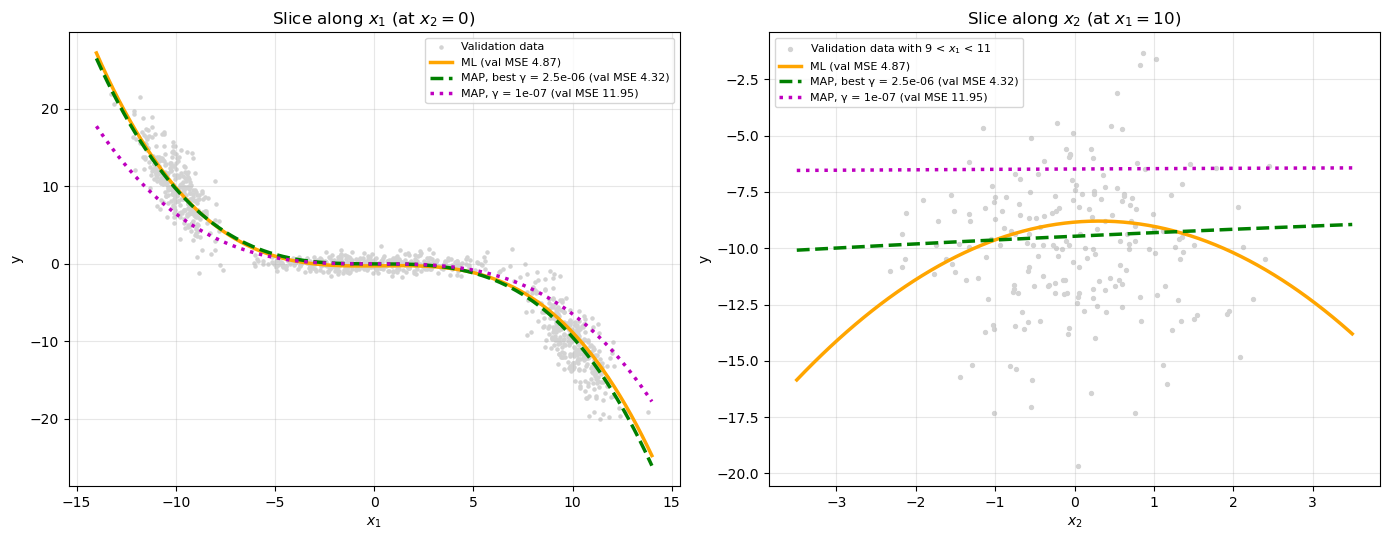

In [6]:
print(f"{'term':>10s}{'w_ML':>12s}{'w_MAP (best γ)':>16s}")
for name, a, b in zip(FEATURE_NAMES, w_ml, w_best):
    print(f"{name:>10s}{a:12.4f}{b:16.4f}")

g_heavy = 1e-7
k_h = np.argmin(np.abs(gammas - g_heavy))
curves_to_plot = [(w_ml, "orange", "-", f"ML (val MSE {mse_ml_val:.2f})"),
                  (w_best, "g", "--", f"MAP, best γ = {g_best:.1e} (val MSE {mse_val[k_best]:.2f})"),
                  (W[k_h], "m", ":", f"MAP, γ = {g_heavy:.0e} (val MSE {mse_val[k_h]:.2f})")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x1_grid = np.linspace(-14, 14, 400)
Xg = np.column_stack([x1_grid, np.zeros_like(x1_grid)])
axes[0].scatter(Xval[:, 0], yval, s=5, c="lightgray", label="Validation data")
for w, col, ls, lab in curves_to_plot:
    axes[0].plot(x1_grid, phi(Xg) @ w, color=col, ls=ls, lw=2.5, label=lab)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("y"); axes[0].set_title("Slice along $x_1$ (at $x_2 = 0$)")

x2_grid = np.linspace(-3.5, 3.5, 200)
Xg2 = np.column_stack([np.full_like(x2_grid, 10.0), x2_grid])
band = np.abs(Xval[:, 0] - 10) < 1
axes[1].scatter(Xval[band, 1], yval[band], s=8, c="lightgray", label="Validation data with 9 < $x_1$ < 11")
for w, col, ls, lab in curves_to_plot:
    axes[1].plot(x2_grid, phi(Xg2) @ w, color=col, ls=ls, lw=2.5, label=lab)
axes[1].set_xlabel("$x_2$"); axes[1].set_ylabel("y"); axes[1].set_title("Slice along $x_2$ (at $x_1 = 10$)")

for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Best gamma per trial: median 4.0e-06, middle 50% between 2.0e-06 and 7.9e-06
Median ML validation MSE = 4.792, median best-MAP validation MSE = 4.226
Median improvement of best MAP over ML = 11.1%
With one fixed gamma = 2.5e-06 in every trial, MAP beat ML in 98% of trials (median improvement 10.2%)


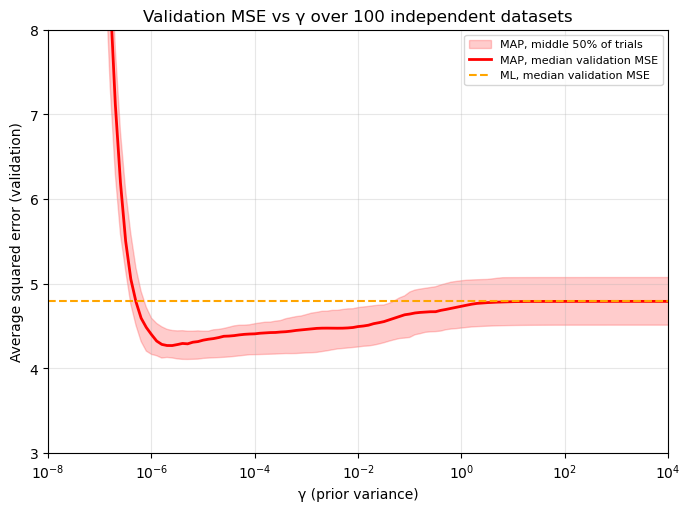

In [7]:
rng_rep = np.random.default_rng(12345)
n_rep = 100
curves, ml_errs, best_g_list = [], [], []
for t in range(n_rep):
    Xt, yt = generate_data(100, rng_rep); Xv, yv = generate_data(1000, rng_rep)
    P, Pv = phi(Xt), phi(Xv)
    wml = np.linalg.solve(P.T @ P, P.T @ yt); s2 = mse(P, yt, wml)
    ml_errs.append(mse(Pv, yv, wml))
    c = [mse(Pv, yv, np.linalg.solve(P.T @ P + (s2 / g) * np.eye(10), P.T @ yt)) for g in gammas]
    curves.append(c); best_g_list.append(gammas[np.argmin(c)])
curves, ml_errs = np.array(curves), np.array(ml_errs)
best_errs = curves.min(axis=1)
k_fix = np.argmin(np.median(curves, axis=0))           

print(f"Best gamma per trial: median {np.median(best_g_list):.1e}, "
      f"middle 50% between {np.percentile(best_g_list, 25):.1e} and {np.percentile(best_g_list, 75):.1e}")
print(f"Median ML validation MSE = {np.median(ml_errs):.3f}, median best-MAP validation MSE = {np.median(best_errs):.3f}")
print(f"Median improvement of best MAP over ML = {np.median(100*(1 - best_errs/ml_errs)):.1f}%")
print(f"With one fixed gamma = {gammas[k_fix]:.1e} in every trial, MAP beat ML in "
      f"{np.mean(curves[:, k_fix] < ml_errs)*100:.0f}% of trials "
      f"(median improvement {np.median(100*(1 - curves[:, k_fix]/ml_errs)):.1f}%)")

plt.figure(figsize=(8, 5.5))
plt.fill_between(gammas, np.percentile(curves, 25, axis=0), np.percentile(curves, 75, axis=0),
                 color="red", alpha=0.2, label="MAP, middle 50% of trials")
plt.semilogx(gammas, np.median(curves, axis=0), "r-", lw=2, label="MAP, median validation MSE")
plt.axhline(np.median(ml_errs), color="orange", ls="--", lw=1.5, label="ML, median validation MSE")
plt.xlim(1e-8, 1e4); plt.ylim(3, 8)
plt.xlabel("γ (prior variance)"); plt.ylabel("Average squared error (validation)")
plt.title(f"Validation MSE vs γ over {n_rep} independent datasets"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
plt.show()